# Clean Air, Healthy Children: analysis walkthrough

This notebook walks through the results of the analysis pipeline in `src/` (run it with `./run_pipeline.sh`).

**It only reads aggregate outputs** (`outputs/`, `site/data/`). It never loads the survey microdata, so it is safe to share and commit with its outputs. To change the analysis, edit the scripts in `src/` and rerun the pipeline, then rerun this notebook.

| Section | What it shows |
|---|---|
| 1 | Data checks: what went in, what was dropped, national sanity checks |
| 2 | How common cough with fast breathing is, by household characteristics |
| 3 | The risk model: odds ratios, validation, explanation |
| 4 | District results: maps, ranking, uncertainty |
| 5 | Robustness of the ranking |
| 6 | Example: how the stove planner allocates a budget |

In [1]:
import json
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT, SITE = ROOT / "outputs", ROOT / "site" / "data"
pd.set_option("display.max_columns", 30, "display.width", 160)

# Sequential single-hue ramp (light -> dark blue) for maps
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
INK2, SURFACE = "#52514e", "#fcfcfb"

## 1. Data checks

Four NISR datasets: **EICV7 2023/24**, **Rwanda DHS 2019-20 and 2025**, **Census 2022**, plus district boundaries from RBC. Full verification of every variable is in `docs/data_inventory.md`.

In [2]:
inv = pd.read_csv(OUT / "inventory.csv")
inv[["key", "file", "size_mb", "rows", "cols"]]

,key,file,size_mb,rows,cols
0,eicv7_household,CS_S01_S5_S7_Household.dta,3.3,15054,112
1,eicv7_person,CS_S0_S1_S2_S3_S4_S6A_S6B_S6C_Person.dta,28.7,62110,157
2,eicv7_poverty,CS_EICV7_poverty_file.dta,2.4,15054,32
3,eicv7_services,CS_S5F_access_to_services.dta,17.6,225810,22
4,dhs2025_kr,RWKR91FL.dta,10.6,7214,1295
5,dhs2025_hr,RWHR91FL.dta,41.3,14427,2452
6,dhs2025_pr,RWPR91FL.dta,30.6,57046,426
7,dhs2019_kr,RWKR81FL.DTA,11.5,8092,1216
8,dhs2019_hr,RWHR81FL.DTA,56.6,12949,3485
9,dhs2019_pr,RWPR81FL.DTA,43.8,55920,581


Every record removed during cleaning is counted:

In [3]:
pd.concat([pd.read_csv(OUT / "cleaning_log_dhs.csv"),
           pd.read_csv(OUT / "cleaning_log_eicv7.csv").assign(survey="EICV7")])

,survey,step,records
0,2019,children in KR,8092
1,2019,alive,7796
2,2019,alive and under 5 (b19<60),7796
3,2019,matched to household recode,7796
4,2019,cough question answered (drop don't know),7758
5,2019,fuel in harmonised set (drop kerosene/other/no...,7758
6,2019,cooking place in/separate/outdoors (drop other...,7758
7,2025,children in KR,7214
8,2025,alive,7000
9,2025,alive and under 5 (b19<60),7000


National sanity checks. The model's average predicted risk for EICV7 children should be close to the rate observed in DHS 2025, and district totals must add up to the Census.

In [4]:
nat = json.loads((OUT / "district" / "national_checks.json").read_text())
pd.Series(nat).to_frame("value")

,value
eicv7_mean_predicted_risk_pct,8.59
dhs2025_observed_pct,8.66
dhs_pooled_observed_pct,7.97
eicv7_children_weighted,1680605
census_children_u5,1731594
census_children_total_matches,True
districts,30
national_children_exposed,1682492
national_children_indoor_smoke,290346
national_children_with_symptoms,148977


DHS and EICV7 describe children's households in very similar ways once categories are harmonised. Wood and straw are merged because DHS 2025 splits them very differently from the other surveys (% of children under 5):

In [5]:
pd.read_csv(OUT / "harmonisation_comparison.csv").set_index(["variable", "category"])

EICV7 2023/24  DHS 2025  DHS 2019-20
variable category                                                      
fuel     charcoal                           20.4      24.9         18.3
         clean                               2.9       3.9          3.0
         kerosene/other                      0.1       0.1          NaN
         other biomass                       0.7       1.1          0.2
         straw/shrubs/grass                 13.4      34.5         17.2
         wood                               62.5      35.5         61.4
         no cooking/missing                  NaN       0.1          NaN
place    in the house                       18.7      16.9         21.5
         outdoors (incl. veranda)           21.1      22.7         21.8
         separate building                  60.2      60.3         56.7
         no cooking/missing                  NaN       0.1          NaN
urban    rural                              71.5      69.5         82.4
         urban                              28.5      30.5         17.6
wealth_q 1                                  19.6      22.5         23.3
         2                                  20.5      19.8         19.2
         3                                  20.3      19.5         19.4
         4                                  20.4      19.3         19.5
         5                                  19.2      18.8         18.6
age      <1y                                19.7      20.6         20.3
         1y                                 19.6      19.9         20.4
         2-4y                               60.7      59.5         59.4
hhsize   1-3                                20.1      22.3         15.9
         4-5                                42.9      44.0         43.6
         6-7                                24.7      24.8         28.0
         8+                                 12.3       8.9         12.5
province 1                                  13.6      14.4         14.1
         2                                  22.3      21.5         20.1
         3                                  21.8      21.8         24.2
         4                                  14.5      13.9         15.1
         5                                  27.8      28.4         26.5

## 2. How common is cough with fast breathing?

Weighted percentages of children under 5 in the pooled DHS 2019-20 + 2025 data, with design-based 95% confidence intervals (clusters within strata).

- **Main outcome:** cough in the last two weeks with short, rapid breathing.
- **Sensitivity outcome:** the strict DHS "ARI symptoms" indicator, which also requires a chest problem.

In [6]:
rates = pd.read_csv(OUT / "descriptives" / "rates_cough_fast.csv")
rates[rates.scope == "pooled"][["variable", "category", "n", "n_events", "pct", "ci_lo", "ci_hi"]]

,variable,category,n,n_events,pct,ci_lo,ci_hi
0,All children,All children,14692,1178,7.97,7.44,8.51
1,Cooking fuel,Charcoal,3017,197,6.20,5.09,7.31
2,Cooking fuel,"Clean (gas, electricity, biogas)",504,27,5.31,3.13,7.48
3,Cooking fuel,"Wood, straw or other biomass",11171,954,8.59,7.98,9.21
4,Where food is cooked,In the house,2962,265,8.82,7.67,9.97
5,Where food is cooked,Outdoors,3017,252,8.25,7.14,9.35
6,Where food is cooked,Separate building,8713,661,7.59,6.95,8.23
7,Fuel and cooking place,Clean fuel,504,27,5.31,3.13,7.48
8,Fuel and cooking place,"Polluting fuel, cooked in the house",2721,251,9.16,7.93,10.39
9,Fuel and cooking place,"Polluting fuel, cooked outside the house",11467,900,7.82,7.23,8.41


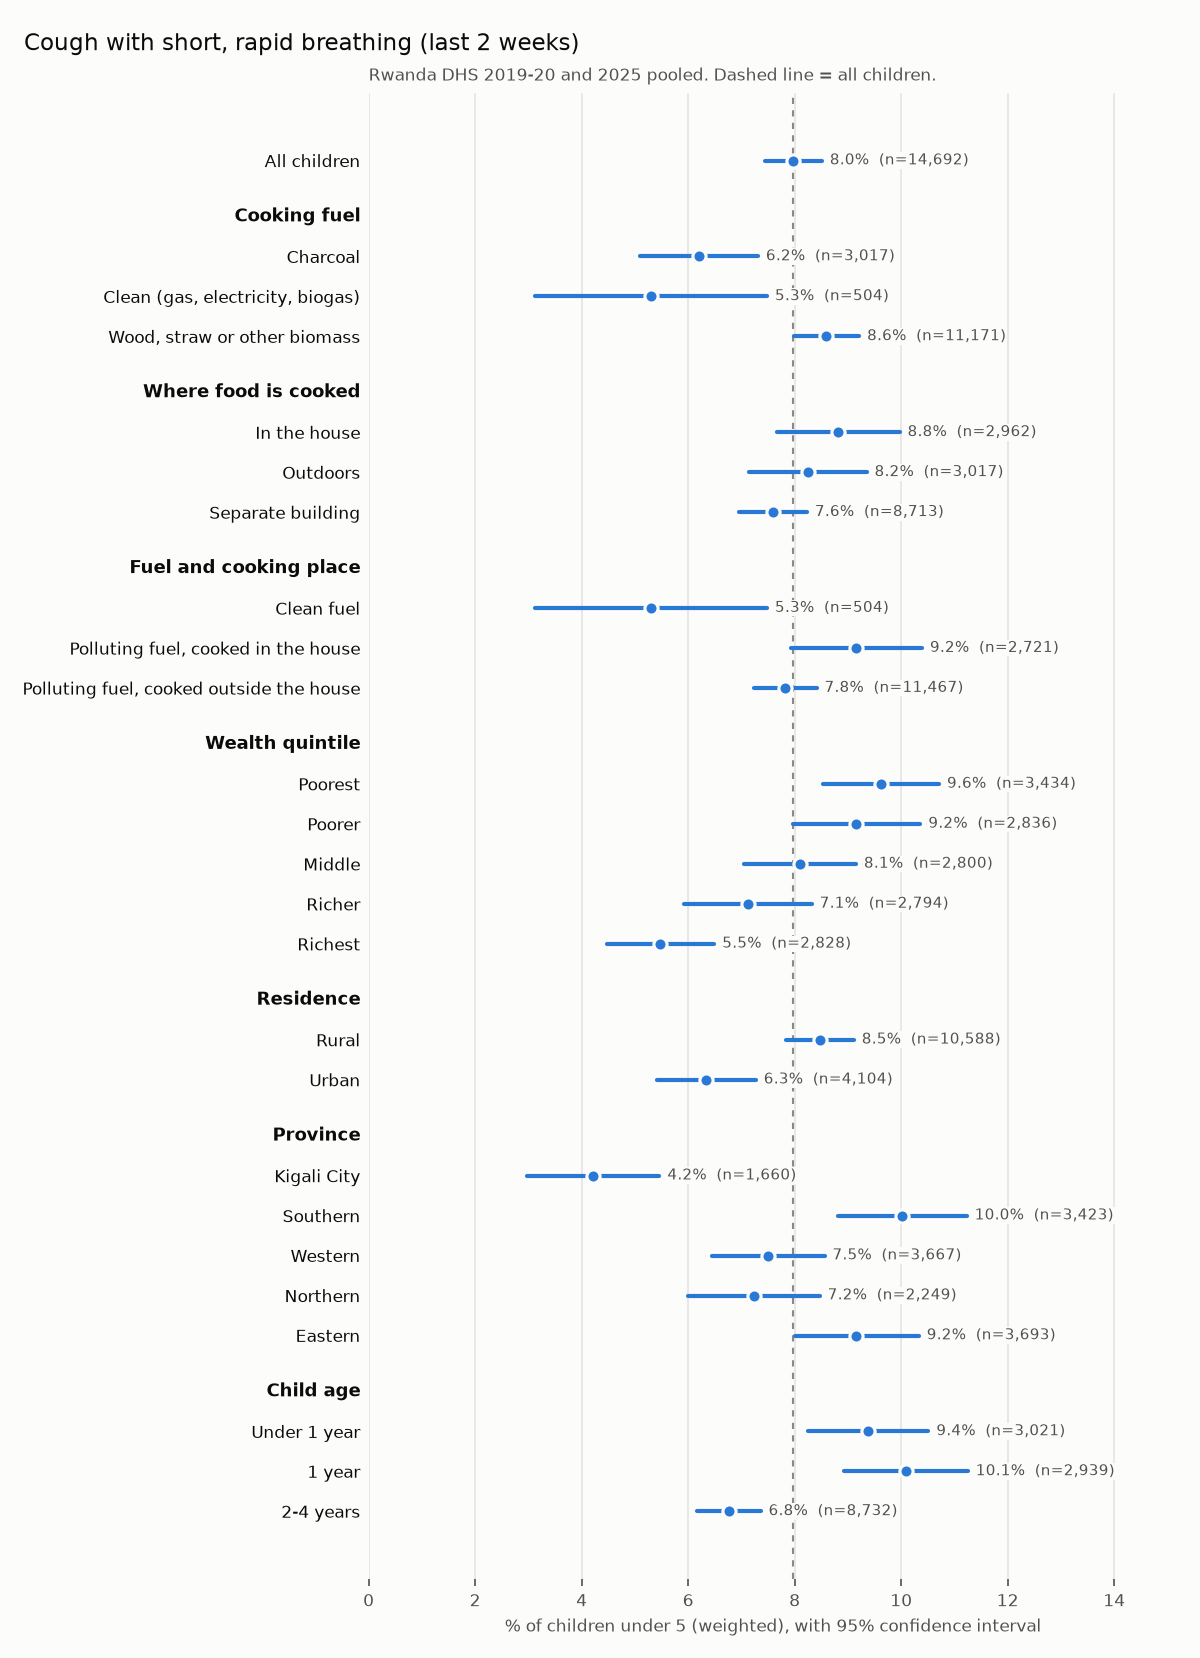

In [7]:
display(Image(OUT / "figures" / "rates_cough_fast.png", width=700))

**Reading:** before adjustment, symptoms are more common in homes using wood or straw than charcoal or clean fuel, and where polluting fuel is burned inside the house. They are also more common among poorer, rural and younger children and outside Kigali. Section 3 checks which of these hold once the factors are considered together.

## 3. The risk model

Survey-weighted logistic regression on 14,692 children, with cluster-robust standard errors. Odds ratios above 1 mean higher risk than the reference group.

In [8]:
ors = pd.read_csv(OUT / "model" / "odds_ratios.csv")
ors[ors.outcome == "cough_fast"][["term", "odds_ratio", "or_lo", "or_hi", "p_value"]].round(3)

,term,odds_ratio,or_lo,or_hi,p_value
0,fuel[charcoal],1.018,0.638,1.623,0.941
1,fuel[wood/straw/biomass],1.081,0.631,1.853,0.776
2,place[separate building],0.882,0.738,1.053,0.164
3,place[in the house],1.024,0.828,1.266,0.829
4,wealth_q[1],1.358,1.002,1.842,0.049
5,wealth_q[2],1.394,1.034,1.879,0.029
6,wealth_q[3],1.290,0.969,1.717,0.082
7,wealth_q[4],1.172,0.874,1.574,0.289
8,rural[1],0.937,0.726,1.210,0.619
9,age_group[<1y],1.401,1.203,1.631,0.000


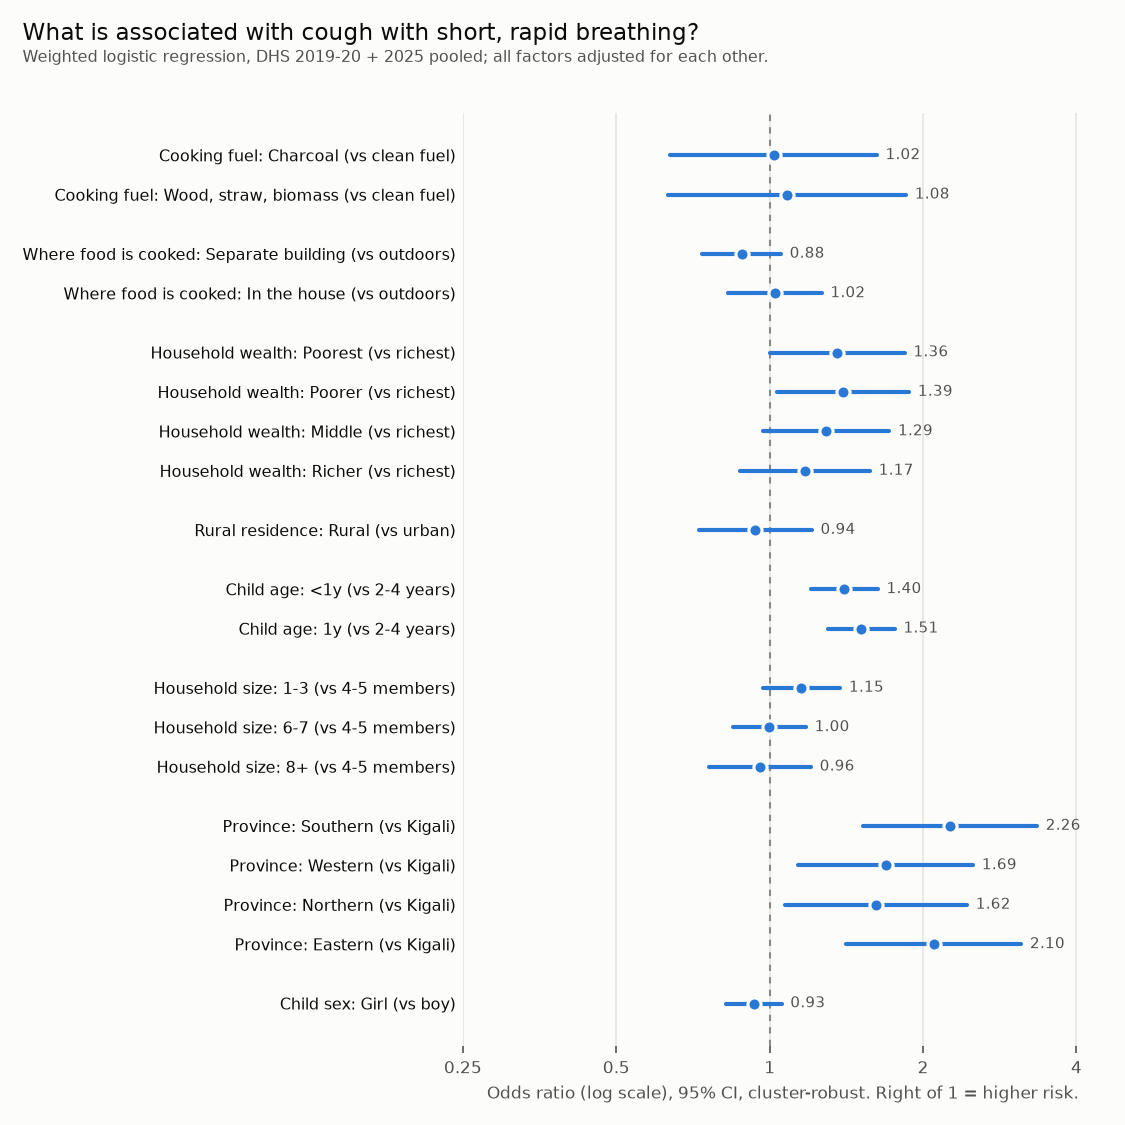

In [9]:
display(Image(OUT / "figures" / "model_odds_ratios_cough_fast.png", width=650))

**Key honest finding.** After adjustment, **cooking fuel and cooking place are not significantly associated** with the symptom (their confidence intervals include 1). Child age, wealth and province are. Clean fuel is rare (3% of children) and concentrated in richer urban households, so household surveys cannot separate the effect of fuel from those factors. The planner therefore uses **published research** for the effect of a cleaner stove, and uses this model for **baseline risk**.

### Validation

5-fold cross-validation **grouped by survey cluster** (so neighbours never appear in both training and test data), repeated 5 times. The logistic model is compared with a shallow XGBoost model and simple baselines.

In [10]:
cv = pd.read_csv(OUT / "model" / "cv_metrics.csv")
cv.groupby(["outcome", "model"])[["auc", "brier", "calib_intercept", "calib_slope"]].mean().round(4)

auc   brier  calib_intercept  calib_slope
outcome    model                                                      
ari        logistic       0.5432  0.0152          -0.0005       0.2941
           no_skill       0.5000  0.0152              NaN          NaN
           province_only  0.5042  0.0152          -0.0003       0.2767
           xgboost        0.5421  0.0152          -0.0003       0.3070
cough_fast logistic       0.5881  0.0729          -0.0011       0.7883
           no_skill       0.5000  0.0734              NaN          NaN
           province_only  0.5557  0.0731          -0.0006       0.8769
           xgboost        0.5842  0.0732          -0.0019       0.6476

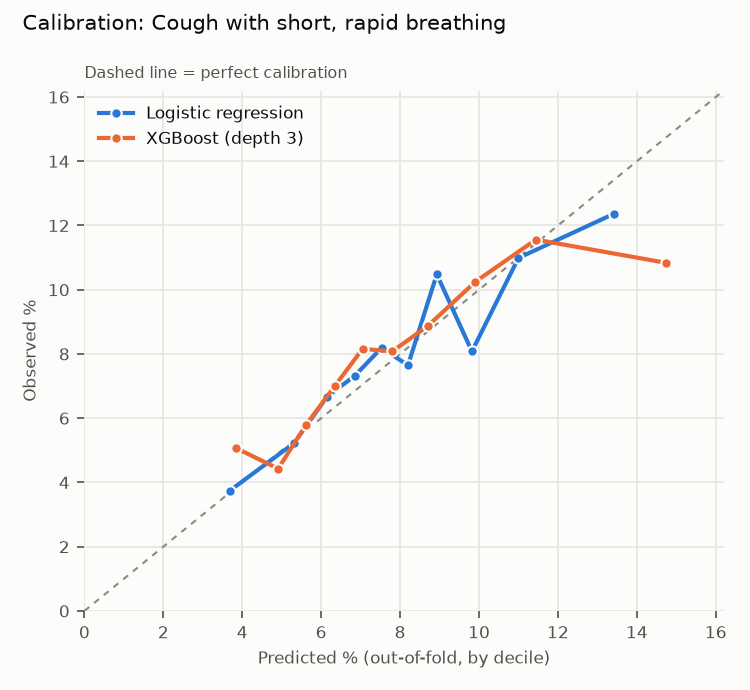

In [11]:
display(Image(OUT / "figures" / "model_calibration_cough_fast.png", width=450))

XGBoost is no better than logistic regression, so the simpler, explainable model is kept. Discrimination is modest (AUC ≈ 0.59), but predictions are well calibrated from about 4% to 13%. That is what matters for comparing groups and districts. The strict ARI model has no useful skill (AUC ≈ 0.54) and is kept only as a sensitivity check.

### Which factors matter most?
Mean absolute SHAP value (log-odds) per factor:

In [12]:
imp = pd.read_csv(OUT / "model" / "feature_importance.csv")
imp[imp.outcome == "cough_fast"].pivot(index="label", columns="model", values="mean_abs_shap").sort_values("logistic", ascending=False).round(3)

model,logistic,xgboost
label,,
Province,0.202,0.164
Child age,0.181,0.183
Household wealth,0.102,0.064
Survey round,0.080,0.091
Where food is cooked,0.067,0.070
Household size,0.046,0.061
Child sex,0.036,0.036
Cooking fuel,0.023,0.077
Rural residence,0.023,0.019


## 4. District results

The model is applied to every child under 5 in EICV7, aggregated to districts, and scaled to Census 2022 counts. Intervals come from a 500-round bootstrap that resamples both the DHS clusters (refitting the model each time) and the EICV7 clusters.

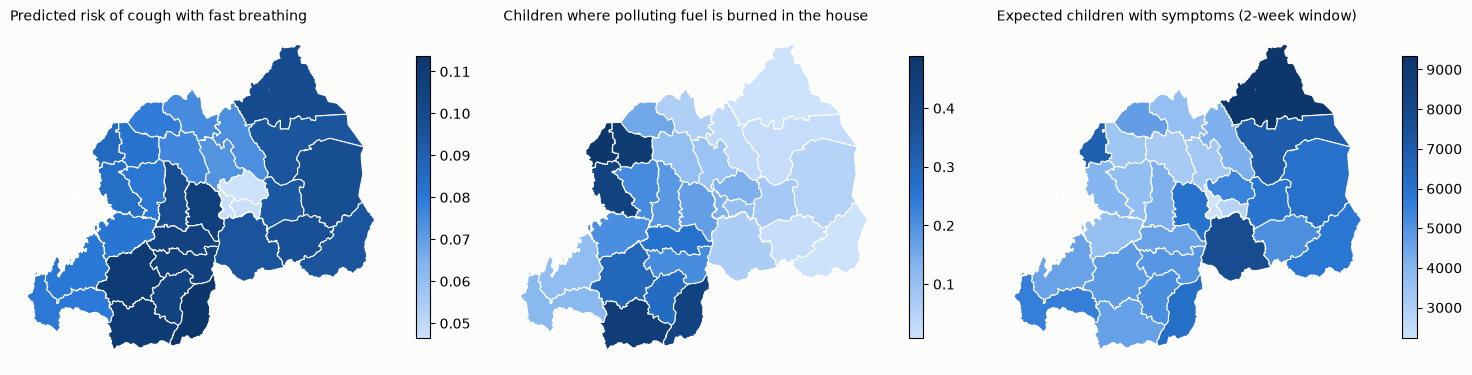

In [13]:
districts = pd.DataFrame(json.loads((SITE / "districts.json").read_text()))
geo = gpd.read_file(SITE / "districts.geojson").merge(districts, left_on="district_code", right_on="code")

fig, axes = plt.subplots(1, 3, figsize=(15, 5), facecolor=SURFACE)
for ax, (col, title, fmt) in zip(axes, [
        ("risk", "Predicted risk of cough with fast breathing", "{:.0%}"),
        ("indoorSmokeShare", "Children where polluting fuel is burned in the house", "{:.0%}"),
        ("childrenWithSymptoms", "Expected children with symptoms (2-week window)", "{:,.0f}")]):
    geo.plot(column=col, cmap=BLUES, edgecolor="white", linewidth=0.8, ax=ax, legend=True,
             legend_kwds={"shrink": 0.6})
    ax.set_title(title, fontsize=10, loc="left")
    ax.set_axis_off()
plt.tight_layout()

Predicted risk is highest in the South and East and lowest in Kigali. **Indoor smoke** follows a different pattern: it is concentrated in the West and South (Rubavu, Nyabihu, Nyaruguru, Gisagara, Rutsiro) and almost absent in the East, where most cooking happens in a separate building.

### Priority ranking

Priority score = children under 5 per polluting-fuel household × their average risk. Multiplied by a stove's effectiveness and usage rate, this is the number of symptom cases averted per stove. The 90% rank interval shows how certain each position is.

In [14]:
rank = pd.read_csv(SITE / "ranking_default.csv")
rank[["priority_rank", "priority_rank_lo", "priority_rank_hi", "priority_tier", "district_name", "province_name",
      "children_u5", "children_indoor_smoke", "risk_pct", "risk_pct_lo", "risk_pct_hi", "children_per_hh"]]

,priority_rank,priority_rank_lo,priority_rank_hi,priority_tier,district_name,province_name,children_u5,children_indoor_smoke,risk_pct,risk_pct_lo,risk_pct_hi,children_per_hh
0,1,1.0,3.00,High,Nyaruguru,Southern,42168.8,19088.493,11.0,9.7,12.5,0.619
1,2,1.0,5.00,High,Gisagara,Southern,54354.6,23521.524,11.4,10.1,12.7,0.572
2,3,2.0,13.00,High,Nyagatare,Eastern,94260.1,894.610,9.9,8.7,11.1,0.574
3,4,3.0,12.00,High,Nyanza,Southern,46837.1,9872.801,10.6,9.3,12.0,0.535
4,5,2.0,13.05,High,Bugesera,Eastern,81757.3,5427.831,9.5,8.4,10.7,0.585
5,6,3.0,15.00,High,Kamonyi,Southern,56348.0,9703.654,10.7,9.5,12.0,0.505
6,7,3.0,16.00,High,Rwamagana,Eastern,63927.2,4900.375,9.3,8.3,10.6,0.576
7,8,4.0,15.05,High,Nyamagabe,Southern,43729.1,13053.066,11.0,9.8,12.3,0.486
8,9,3.0,16.00,High,Rubavu,Western,78964.3,38632.335,8.6,7.4,9.8,0.613
9,10,3.0,17.00,High,Rusizi,Western,69849.3,8521.645,8.0,7.0,9.0,0.655


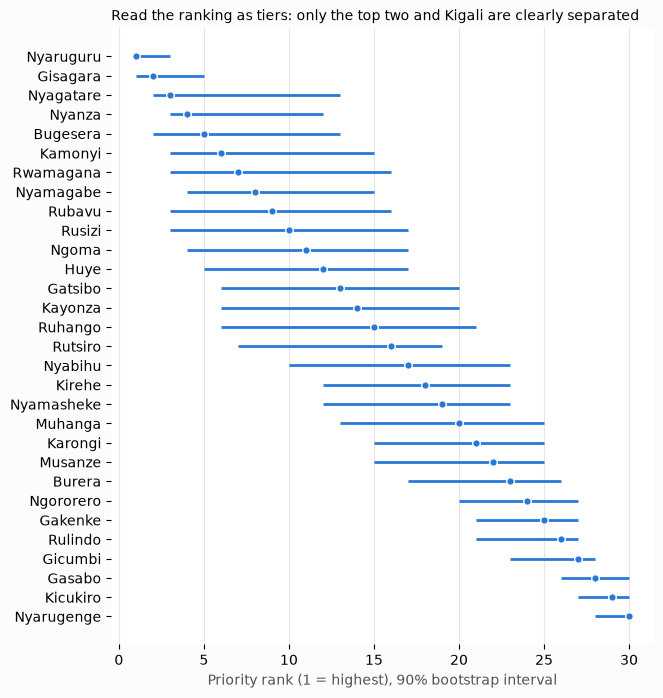

In [15]:
d = districts.sort_values("priorityRank")
fig, ax = plt.subplots(figsize=(7, 8), facecolor=SURFACE)
ax.hlines(d["name"], d.priorityRankLo, d.priorityRankHi, color="#2a78d6", lw=2)
ax.scatter(d.priorityRank, d["name"], color="#2a78d6", s=30, zorder=3, edgecolor=SURFACE)
ax.invert_yaxis()
ax.set_xlabel("Priority rank (1 = highest), 90% bootstrap interval", color=INK2)
ax.set_title("Read the ranking as tiers: only the top two and Kigali are clearly separated", fontsize=10, loc="left")
ax.grid(axis="x", color="#e6e5e1")
for s in ax.spines.values():
    s.set_visible(False)

### Why is a district high risk?

For each district, how much each factor pushes average predicted risk above (+) or below (−) the national average, in percentage points (district-average linear SHAP). The example below is the top-ranked district:

In [16]:
top = districts.sort_values("priorityRank").iloc[0]
print(top["name"], "- predicted risk", f"{top.risk:.1%}")
pd.DataFrame(top.whyFactors)[["factor", "pp"]]

Nyaruguru - predicted risk 11.0%


,factor,pp
0,Province,1.91
1,Household wealth,0.43
2,Where food is cooked,0.26
3,Rural residence,-0.13
4,Cooking fuel,0.10
5,Household size,-0.09
6,Child age,-0.08
7,Child sex,0.01


## 5. Robustness

The ranking recomputed under alternative choices: Spearman correlation with the main ranking, and how many of the top 10 districts stay in the top 10.

In [17]:
pd.read_csv(OUT / "district" / "robustness.csv")

,variant,spearman_vs_main,top10_overlap,entered_top10,left_top10
0,Strict ARI outcome,0.629,5,"Karongi, Rutsiro, Nyabihu, Ngororero, Nyamasheke","Nyanza, Nyamagabe, Kamonyi, Rwamagana, Bugesera"
1,DHS 2025 only,0.863,8,"Huye, Ngoma","Rubavu, Rusizi"
2,Without province,0.779,7,"Rutsiro, Nyamasheke, Ngoma","Nyamagabe, Kamonyi, Rwamagana"
3,Without wealth,0.989,8,"Huye, Ngoma","Rubavu, Rusizi"
4,Without household size,0.997,10,NaN,NaN
5,XGBoost instead of logistic,0.919,8,"Huye, Ngoma","Rubavu, Rusizi"


The ranking is stable to the model type, the survey round and most predictors. It changes under the strict ARI outcome, but that model has no predictive skill, so this variant is reported and not used.

## 6. Example: allocating a stove budget

The website's planner follows the same greedy rule as below. Districts are served in order of cases averted per stove, each up to its number of polluting-fuel households. Stove cost, usage and effect come from `site/data/assumptions.json`, where every value has a source.

Trials and observational studies disagree on how much a cleaner stove reduces child respiratory illness, so **cases averted are shown as a range**: from the randomised-trial estimate (low) to an upper bound from observational studies (high). **Children reached** is the more certain number.

In [18]:
assumptions = json.loads((SITE / "assumptions.json").read_text())
stoves = pd.DataFrame(assumptions["stoves"]).set_index("id")
stoves[["name", "cost", "usage", "effect"]]

,name,cost,usage,effect
id,,,,
lpg,LPG gas stove kit,150000,0.90,"{'trial': 0.04, 'observational': 0.44}"
ics,Improved biomass cookstove (Tier 3),36000,0.83,"{'trial': 0.16, 'observational': 0.21}"
epc,Electric pressure cooker,85000,0.41,"{'trial': 0.04, 'observational': 0.44}"


In [19]:
def plan(districts, stove, budget, scenario):
    n = int(budget // stove.cost)
    e = stove.effect[scenario]
    rows = districts.assign(per_stove=districts.childrenPerHH * districts.riskExposed * e * stove.usage)
    rows = rows.sort_values("priorityScore", ascending=False).reset_index(drop=True)
    left, out = n, []
    for _, r in rows.iterrows():
        give = min(left, int(r.pollutingHH))
        left -= give
        out.append({"district": r["name"], "stoves": give, "children_reached": give * r.childrenPerHH * stove.usage,
                    "cases_averted_2wk": give * r.per_stove})
    return pd.DataFrame(out), n - left


budget = assumptions["defaults"]["budgetRWF"]
stove = stoves.loc[assumptions["defaults"]["stove"]]
low, used = plan(districts, stove, budget, "trial")
high, _ = plan(districts, stove, budget, "observational")
print(f"{stove['name']}: budget {budget:,} RWF buys {used:,} stoves")
print(f"Children under 5 reached: {low.children_reached.sum():,.0f}")
print(f"Cases of cough with fast breathing averted in a 2-week window: "
      f"{low.cases_averted_2wk.sum():,.0f} (trial) to {high.cases_averted_2wk.sum():,.0f} (observational upper bound)")
low.assign(cases_averted_high=high.cases_averted_2wk)[low.stoves > 0].round(0)

Improved biomass cookstove (Tier 3): budget 5,000,000,000 RWF buys 138,888 stoves
Children under 5 reached: 68,781
Cases of cough with fast breathing averted in a 2-week window: 1,230 (trial) to 1,614 (observational upper bound)


,district,stoves,children_reached,cases_averted_2wk,cases_averted_high
0,Nyaruguru,73434,37722.0,665.0,872.0
1,Gisagara,65454,31059.0,565.0,742.0
